### RANDOM FOREST- CLASSIFIER

In [10]:
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay


load file, seperate target and features, train test split

In [2]:
df=pd.read_csv("Heart_dataset")

X = df.drop(columns="HeartDisease")
y = df["HeartDisease"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

fill missing values and convert categorical to numerical columns

In [3]:
for column in X_train.columns:
    if pd.api.types.is_numeric_dtype(X_train[column]):
        fill_value = X_train[column].median()
    else:
        modes = X_train[column].mode(dropna=True)
        fill_value = modes.iloc[0] if not modes.empty else "Unknown"

    X_train[column] = X_train[column].fillna(fill_value)
    X_test[column] = X_test[column].fillna(fill_value)

X_train = pd.get_dummies(X_train, dtype=int)
X_test = pd.get_dummies(X_test, dtype=int)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)


Create and train the model

In [6]:
model = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)
model.fit(X_train, y_train);

Predict and evaluate

Accuracy: 0.908

Confusion matrix:
[[71 11]
 [ 6 96]]

Classification report:
                  precision    recall  f1-score   support

No heart disease       0.92      0.87      0.89        82
   Heart disease       0.90      0.94      0.92       102

        accuracy                           0.91       184
       macro avg       0.91      0.90      0.91       184
    weighted avg       0.91      0.91      0.91       184



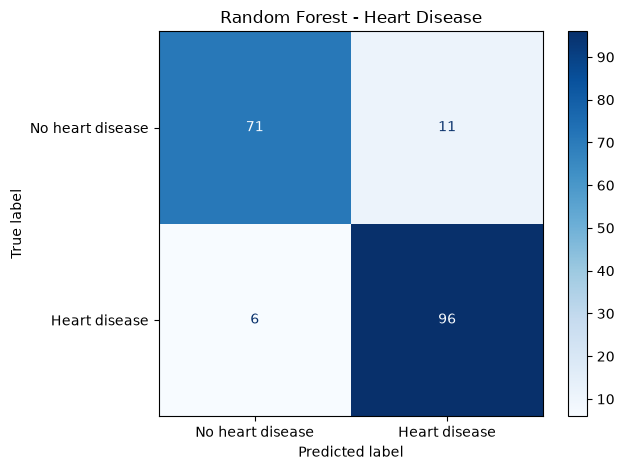

In [11]:
predictions = model.predict(X_test)
print("Accuracy:", round(accuracy_score(y_test, predictions), 3))
print("\nConfusion matrix:")
print(confusion_matrix(y_test, predictions))

print("\nClassification report:")
print(classification_report(
    y_test,
    predictions,
    target_names=["No heart disease", "Heart disease"],
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    predictions,
    display_labels=["No heart disease", "Heart disease"],
    cmap="Blues"
)

plt.title("Random Forest - Heart Disease")
plt.tight_layout()
plt.show()